# Testing Trained Pangenomic GAT Models

This notebook:
1. **Visualizes existing predictions** from `results/predictions_fold*.npz`
2. **Loads trained models** from `results/model_fold*.pt`
3. **Tests models on pchic_saikat data** to generate new predictions
4. **Compares performance** across folds and data sources

---

In [13]:
import sys
from pathlib import Path

# Setup paths
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "codes"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    accuracy_score, confusion_matrix, classification_report
)
import torch
from tqdm.auto import tqdm

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

# Paths
RESULTS_DIR = PROJECT_ROOT / "results"
PCHIC_DATA = PROJECT_ROOT / "pchic_saikat" / "Gene_Annotated_PCHIC_Loops_Selected BEST TO USE"
RNA_SEQ = PROJECT_ROOT / "pchic_saikat" / "rnaseq_results"
TEST_OUTPUT = RESULTS_DIR / "test_on_pchic_saikat"
TEST_OUTPUT.mkdir(exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Results dir: {RESULTS_DIR}")
print(f"PCHi-C data: {PCHIC_DATA}")
print(f"RNA-seq data: {RNA_SEQ}")
print(f"Test output: {TEST_OUTPUT}")
print(f"\nDevice: {torch.device('cuda' if torch.cuda.is_available() else 'cpu')}")

Project root: /home/subhadip/pchic_gat
Results dir: /home/subhadip/pchic_gat/results
PCHi-C data: /home/subhadip/pchic_gat/pchic_saikat/Gene_Annotated_PCHIC_Loops_Selected BEST TO USE
RNA-seq data: /home/subhadip/pchic_gat/pchic_saikat/rnaseq_results
Test output: /home/subhadip/pchic_gat/results/test_on_pchic_saikat

Device: cuda


---
## Part 1: Visualize Existing Predictions

Load and analyze the saved predictions from previous training runs.

In [14]:
# Load all fold predictions
predictions = {}
for fold in range(5):
    pred_file = RESULTS_DIR / f"predictions_fold{fold}.npz"
    if pred_file.exists():
        predictions[fold] = np.load(pred_file)
        print(f"Fold {fold}: {pred_file.name}")
        print(f"  Keys: {list(predictions[fold].keys())}")
        print(f"  Samples: {len(predictions[fold]['expr_y'])} genes")
        print(f"  Links: {len(predictions[fold]['link_y'])} edges")
    else:
        print(f"Fold {fold}: NOT FOUND")

print(f"\nLoaded {len(predictions)} folds")

Fold 0: predictions_fold0.npz
  Keys: ['link_p', 'link_y', 'expr_p', 'expr_y', 'tau_p', 'tau_y', 'tis_p', 'tis_y']
  Samples: 72724 genes
  Links: 367156 edges
Fold 1: predictions_fold1.npz
  Keys: ['link_p', 'link_y', 'expr_p', 'expr_y', 'tau_p', 'tau_y', 'tis_p', 'tis_y']
  Samples: 72724 genes
  Links: 353530 edges
Fold 2: predictions_fold2.npz
  Keys: ['link_p', 'link_y', 'expr_p', 'expr_y', 'tau_p', 'tau_y', 'tis_p', 'tis_y']
  Samples: 72723 genes
  Links: 358376 edges
Fold 3: predictions_fold3.npz
  Keys: ['link_p', 'link_y', 'expr_p', 'expr_y', 'tau_p', 'tau_y', 'tis_p', 'tis_y']
  Samples: 72723 genes
  Links: 359724 edges
Fold 4: predictions_fold4.npz
  Keys: ['link_p', 'link_y', 'expr_p', 'expr_y', 'tau_p', 'tau_y', 'tis_p', 'tis_y']
  Samples: 72723 genes
  Links: 358294 edges

Loaded 5 folds


In [15]:
# Compute metrics for each fold
metrics_rows = []

for fold, pred in predictions.items():
    # Filter out invalid samples (where y == -1) for each task
    
    # Link prediction metrics
    link_valid = pred['link_y'] >= 0
    if link_valid.sum() > 0 and len(np.unique(pred['link_y'][link_valid])) > 1:
        link_auroc = roc_auc_score(pred['link_y'][link_valid], pred['link_p'][link_valid])
        link_auprc = average_precision_score(pred['link_y'][link_valid], pred['link_p'][link_valid])
        link_f1 = f1_score(pred['link_y'][link_valid], pred['link_p'][link_valid] > 0.5)
    else:
        link_auroc = link_auprc = link_f1 = np.nan
    
    # Expression prediction metrics
    expr_valid = pred['expr_y'] >= 0
    if expr_valid.sum() > 0 and len(np.unique(pred['expr_y'][expr_valid])) > 1:
        expr_auroc = roc_auc_score(pred['expr_y'][expr_valid], pred['expr_p'][expr_valid])
        expr_auprc = average_precision_score(pred['expr_y'][expr_valid], pred['expr_p'][expr_valid])
        expr_f1 = f1_score(pred['expr_y'][expr_valid], pred['expr_p'][expr_valid] > 0.5)
    else:
        expr_auroc = expr_auprc = expr_f1 = np.nan
    
    # Tau (tissue-specificity) metrics
    tau_valid = pred['tau_y'] >= 0
    if tau_valid.sum() > 0 and len(np.unique(pred['tau_y'][tau_valid])) > 1:
        tau_auroc = roc_auc_score(pred['tau_y'][tau_valid], pred['tau_p'][tau_valid])
        tau_auprc = average_precision_score(pred['tau_y'][tau_valid], pred['tau_p'][tau_valid])
        tau_f1 = f1_score(pred['tau_y'][tau_valid], pred['tau_p'][tau_valid] > 0.5)
    else:
        tau_auroc = tau_auprc = tau_f1 = np.nan
    
    # Tissue classification metrics (no -1 filtering needed for multi-class)
    tis_pred = pred['tis_p'].argmax(axis=1)
    tis_acc = accuracy_score(pred['tis_y'], tis_pred)
    tis_f1 = f1_score(pred['tis_y'], tis_pred, average='macro')
    
    metrics_rows.append({
        'fold': fold,
        'link_auroc': link_auroc,
        'link_auprc': link_auprc,
        'link_f1': link_f1,
        'expr_auroc': expr_auroc,
        'expr_auprc': expr_auprc,
        'expr_f1': expr_f1,
        'tau_auroc': tau_auroc,
        'tau_auprc': tau_auprc,
        'tau_f1': tau_f1,
        'tissue_acc': tis_acc,
        'tissue_f1': tis_f1,
    })

metrics_df = pd.DataFrame(metrics_rows)
print("\n" + "="*80)
print("EXISTING PREDICTIONS: PERFORMANCE SUMMARY")
print("="*80)
print(metrics_df.to_string(index=False))
print("\nMean across folds:")
print(metrics_df.mean(numeric_only=True).to_string())

# Save metrics
metrics_df.to_csv(TEST_OUTPUT / "existing_predictions_metrics.csv", index=False)
print(f"\nMetrics saved to: {TEST_OUTPUT / 'existing_predictions_metrics.csv'}")


EXISTING PREDICTIONS: PERFORMANCE SUMMARY
 fold  link_auroc  link_auprc  link_f1  expr_auroc  expr_auprc  expr_f1  tau_auroc  tau_auprc   tau_f1  tissue_acc  tissue_f1
    0         1.0         1.0 1.000000    0.873341    0.892933 0.831114   0.870081   0.686822 0.645894    0.908600   0.732491
    1         1.0         1.0 0.999941    0.843790    0.854528 0.823904   0.840225   0.661282 0.566670    0.712640   0.460244
    2         1.0         1.0 0.999997    0.824073    0.846999 0.813664   0.806360   0.556821 0.475137    0.577548   0.360849
    3         1.0         1.0 0.999994    0.882211    0.899468 0.841357   0.889938   0.736584 0.686054    0.903414   0.729565
    4         1.0         1.0 1.000000    0.882723    0.902954 0.836772   0.866161   0.658533 0.623592    0.908475   0.757426

Mean across folds:
fold          2.000000
link_auroc    1.000000
link_auprc    1.000000
link_f1       0.999986
expr_auroc    0.861228
expr_auprc    0.879376
expr_f1       0.829362
tau_auroc     0.8545

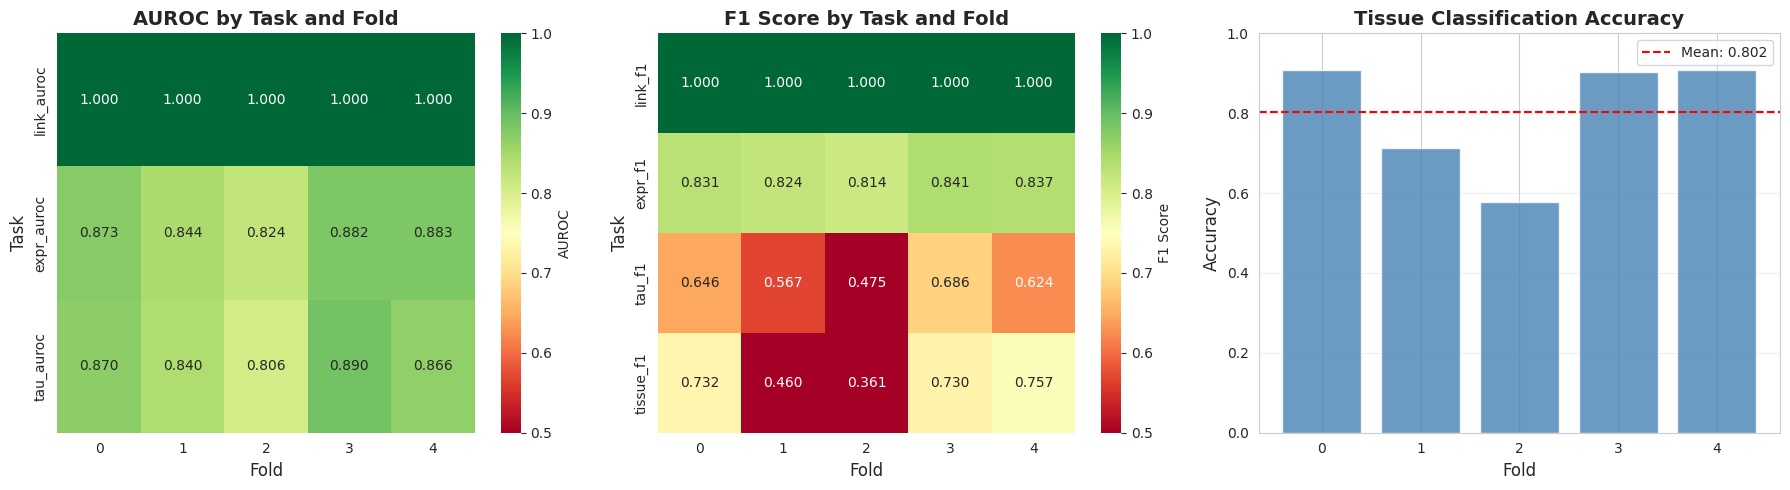

Figure saved to: /home/subhadip/pchic_gat/results/test_on_pchic_saikat/existing_predictions_summary.png


In [16]:
# Visualization 1: Performance heatmap across folds
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# AUROC heatmap
auroc_data = metrics_df[['fold', 'link_auroc', 'expr_auroc', 'tau_auroc']].set_index('fold').T
sns.heatmap(auroc_data, annot=True, fmt='.3f', cmap='RdYlGn', vmin=0.5, vmax=1.0, 
            cbar_kws={'label': 'AUROC'}, ax=axes[0])
axes[0].set_title('AUROC by Task and Fold', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Task', fontsize=12)
axes[0].set_xlabel('Fold', fontsize=12)

# F1 heatmap
f1_data = metrics_df[['fold', 'link_f1', 'expr_f1', 'tau_f1', 'tissue_f1']].set_index('fold').T
sns.heatmap(f1_data, annot=True, fmt='.3f', cmap='RdYlGn', vmin=0.5, vmax=1.0,
            cbar_kws={'label': 'F1 Score'}, ax=axes[1])
axes[1].set_title('F1 Score by Task and Fold', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Task', fontsize=12)
axes[1].set_xlabel('Fold', fontsize=12)

# Tissue classification accuracy
axes[2].bar(metrics_df['fold'], metrics_df['tissue_acc'], color='steelblue', alpha=0.8)
axes[2].axhline(metrics_df['tissue_acc'].mean(), color='red', linestyle='--', 
                label=f"Mean: {metrics_df['tissue_acc'].mean():.3f}")
axes[2].set_title('Tissue Classification Accuracy', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Fold', fontsize=12)
axes[2].set_ylabel('Accuracy', fontsize=12)
axes[2].set_ylim(0, 1.0)
axes[2].legend()
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(TEST_OUTPUT / "existing_predictions_summary.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"Figure saved to: {TEST_OUTPUT / 'existing_predictions_summary.png'}")

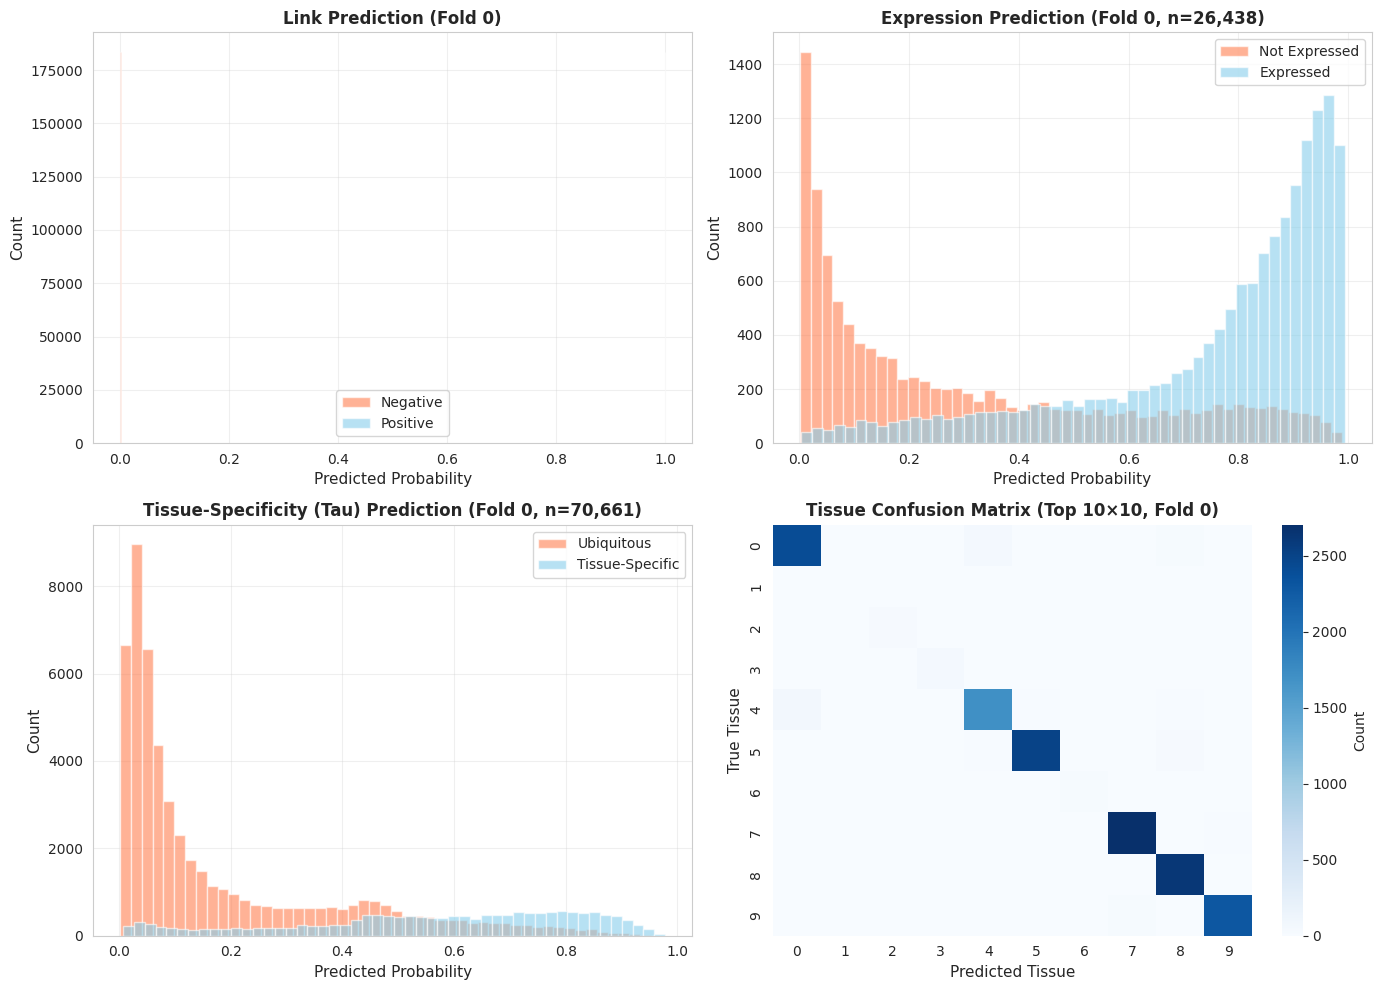

Figure saved to: /home/subhadip/pchic_gat/results/test_on_pchic_saikat/prediction_distributions.png


In [17]:
# Visualization 2: Prediction distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Use fold 0 for detailed visualization
fold0 = predictions[0]

# Link prediction (no -1 values)
axes[0, 0].hist(fold0['link_p'][fold0['link_y'] == 0], bins=50, alpha=0.6, label='Negative', color='coral')
axes[0, 0].hist(fold0['link_p'][fold0['link_y'] == 1], bins=50, alpha=0.6, label='Positive', color='skyblue')
axes[0, 0].set_xlabel('Predicted Probability', fontsize=11)
axes[0, 0].set_ylabel('Count', fontsize=11)
axes[0, 0].set_title('Link Prediction (Fold 0)', fontsize=12, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Expression prediction (filter out -1)
expr_valid = fold0['expr_y'] >= 0
expr_y_valid = fold0['expr_y'][expr_valid]
expr_p_valid = fold0['expr_p'][expr_valid]
axes[0, 1].hist(expr_p_valid[expr_y_valid == 0], bins=50, alpha=0.6, label='Not Expressed', color='coral')
axes[0, 1].hist(expr_p_valid[expr_y_valid == 1], bins=50, alpha=0.6, label='Expressed', color='skyblue')
axes[0, 1].set_xlabel('Predicted Probability', fontsize=11)
axes[0, 1].set_ylabel('Count', fontsize=11)
axes[0, 1].set_title(f'Expression Prediction (Fold 0, n={expr_valid.sum():,})', fontsize=12, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Tau prediction (filter out -1)
tau_valid = fold0['tau_y'] >= 0
tau_y_valid = fold0['tau_y'][tau_valid]
tau_p_valid = fold0['tau_p'][tau_valid]
axes[1, 0].hist(tau_p_valid[tau_y_valid == 0], bins=50, alpha=0.6, label='Ubiquitous', color='coral')
axes[1, 0].hist(tau_p_valid[tau_y_valid == 1], bins=50, alpha=0.6, label='Tissue-Specific', color='skyblue')
axes[1, 0].set_xlabel('Predicted Probability', fontsize=11)
axes[1, 0].set_ylabel('Count', fontsize=11)
axes[1, 0].set_title(f'Tissue-Specificity (Tau) Prediction (Fold 0, n={tau_valid.sum():,})', fontsize=12, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Tissue classification confusion matrix (top 10x10 for visibility)
tis_pred = fold0['tis_p'].argmax(axis=1)
cm = confusion_matrix(fold0['tis_y'], tis_pred)
# Show top 10x10 corner
cm_subset = cm[:10, :10]
sns.heatmap(cm_subset, annot=False, cmap='Blues', ax=axes[1, 1], cbar_kws={'label': 'Count'})
axes[1, 1].set_xlabel('Predicted Tissue', fontsize=11)
axes[1, 1].set_ylabel('True Tissue', fontsize=11)
axes[1, 1].set_title('Tissue Confusion Matrix (Top 10×10, Fold 0)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(TEST_OUTPUT / "prediction_distributions.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"Figure saved to: {TEST_OUTPUT / 'prediction_distributions.png'}")

---
## Part 2: Load Trained Models

Load the saved PyTorch models and inspect their architecture.

In [18]:
# Load model checkpoint to inspect structure
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_path = RESULTS_DIR / "model_fold0.pt"

if model_path.exists():
    checkpoint = torch.load(model_path, map_location=device)
    print("Checkpoint keys:")
    for key in checkpoint.keys():
        if isinstance(checkpoint[key], dict):
            print(f"  {key}: dict with keys {list(checkpoint[key].keys())}")
        elif isinstance(checkpoint[key], (int, float, str)):
            print(f"  {key}: {checkpoint[key]}")
        else:
            print(f"  {key}: {type(checkpoint[key])}")
    
    # Check if model state dict is present
    if 'model_state_dict' in checkpoint:
        state_dict = checkpoint['model_state_dict']
        print(f"\nModel has {len(state_dict)} parameter tensors")
        print("\nSample parameter names:")
        for i, key in enumerate(list(state_dict.keys())[:10]):
            print(f"  {key}: {state_dict[key].shape}")
        
        # Count total parameters
        total_params = sum(p.numel() for p in state_dict.values())
        print(f"\nTotal parameters: {total_params:,}")
        print(f"Model size: {model_path.stat().st_size / 1e6:.1f} MB")
else:
    print(f"Model file not found: {model_path}")

/tmp/ipykernel_1488746/2462333686.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(model_path, map_location=device)


Checkpoint keys:
  state_dict: dict with keys ['link_bilinear', 'seq.stem.0.weight', 'seq.stem.0.bias', 'seq.stem.1.w', 'seq.blocks.0.n1.w', 'seq.blocks.0.n2.w', 'seq.blocks.0.mixer.in_proj.weight', 'seq.blocks.0.mixer.in_proj.bias', 'seq.blocks.0.mixer.out_proj.weight', 'seq.blocks.0.mixer.out_proj.bias', 'seq.blocks.0.mixer.short_filter.weight', 'seq.blocks.0.mixer.short_filter.bias', 'seq.blocks.0.mixer.filter_fn.bias', 'seq.blocks.0.mixer.filter_fn.pos_emb.z', 'seq.blocks.0.mixer.filter_fn.pos_emb.t', 'seq.blocks.0.mixer.filter_fn.implicit_filter.0.weight', 'seq.blocks.0.mixer.filter_fn.implicit_filter.0.bias', 'seq.blocks.0.mixer.filter_fn.implicit_filter.1.freq', 'seq.blocks.0.mixer.filter_fn.implicit_filter.2.weight', 'seq.blocks.0.mixer.filter_fn.implicit_filter.2.bias', 'seq.blocks.0.mixer.filter_fn.implicit_filter.3.freq', 'seq.blocks.0.mixer.filter_fn.implicit_filter.4.weight', 'seq.blocks.0.mixer.filter_fn.implicit_filter.4.bias', 'seq.blocks.0.mixer.filter_fn.implicit_filt

---
## Part 3: Prepare pchic_saikat Data

Load and process the pchic_saikat data for testing.

In [19]:
# Load RNA-seq data
print("Loading RNA-seq data...")
rna_tpm = pd.read_csv(RNA_SEQ / "rnaseq.rsem_genes_tpm.txt", sep='\t')
print(f"RNA-seq shape: {rna_tpm.shape}")
print(f"Columns: {rna_tpm.columns[:10].tolist()}...")
print(f"Genes: {len(rna_tpm)}")
print(f"Samples: {len(rna_tpm.columns) - 2}")  # Minus gene_id and gene_name

# Load PCHi-C loops
print("\nLoading PCHi-C loop files...")
loop_files = sorted(PCHIC_DATA.glob("*_merged_loop.txt"))
print(f"Found {len(loop_files)} tissue loop files")

# Parse tissue names from filenames
tissues = []
for f in loop_files[:5]:  # Show first 5
    # Format: {ID}_{Tissue}_merged_loop.txt
    parts = f.stem.split('_')
    tissue = '_'.join(parts[1:-2])  # Everything between ID and 'merged_loop'
    tissues.append(tissue)
    print(f"  {f.name} → tissue: {tissue}")

print(f"\nTotal tissues available: {len(loop_files)}")

Loading RNA-seq data...
RNA-seq shape: (57420, 196)
Columns: ['gene_id', 'gene_name', '0001_GSE86189_Thymus_0', '0001_GSE86189_Thymus_1', '0001_GSE86189_Thymus_2', '0001_GSE86189_Thymus_3', '0001_GSE86189_Thymus_4', '0002_GSE86189_Embryo - Trophoblast_0', '0003_GSE86189_Spleen_0', '0003_GSE86189_Spleen_1']...
Genes: 57420
Samples: 194

Loading PCHi-C loop files...
Found 46 tissue loop files
  0002_Embryo - Trophoblast_merged_loop.txt → tissue: Embryo - Trophoblast
  0003_Spleen_merged_loop.txt → tissue: Spleen
  0004_Small Intestine - Terminal Ileum_merged_loop.txt → tissue: Small Intestine - Terminal Ileum
  0008_Muscle - Skeletal_merged_loop.txt → tissue: Muscle - Skeletal
  0009_Pancreas_merged_loop.txt → tissue: Pancreas

Total tissues available: 46


In [20]:
# Inspect one loop file to understand structure
if len(loop_files) == 0:
    print("ERROR: No loop files found!")
    print(f"Check that {PCHIC_DATA} exists and contains *_merged_loop.txt files")
else:
    sample_loop = loop_files[0]
    print(f"Inspecting: {sample_loop.name}\n")

    # Read first few rows
    loops = pd.read_csv(sample_loop, sep='\t', nrows=10)
    print("Columns:")
    for i, col in enumerate(loops.columns):
        print(f"  {i}: {col}")

    print("\nFirst 3 rows:")
    print(loops.head(3).to_string())

    # Load full file to get statistics
    loops_full = pd.read_csv(sample_loop, sep='\t')
    print(f"\nTotal loops in this tissue: {len(loops_full):,}")
    
    # Safely get score statistics
    score_col = loops_full.iloc[:, 3]
    if not score_col.isna().all():
        print(f"Score range: [{score_col.min():.2f}, {score_col.max():.2f}]")
    else:
        print("Score range: [N/A - all values are NaN]")
    
    # Safely get N_reads statistics
    reads_col = loops_full.iloc[:, 2]
    if not reads_col.isna().all():
        print(f"N_reads range: [{reads_col.min():.0f}, {reads_col.max():.0f}]")
    else:
        print("N_reads range: [N/A - all values are NaN]")

    # Count unique genes
    if len(loops_full.columns) >= 11:
        bait_genes = loops_full.iloc[:, 9].dropna().unique()  # Column 9: bait_gene
        other_genes = loops_full.iloc[:, 10].dropna().unique()  # Column 10: other_gene
        print(f"Unique bait genes: {len(bait_genes)}")
        print(f"Unique other-end genes: {len(other_genes)}")
    else:
        print(f"\nWARNING: Expected at least 11 columns, found {len(loops_full.columns)}")

Inspecting: 0002_Embryo - Trophoblast_merged_loop.txt

Columns:
  0: bait_frag
  1: other_frag
  2: N_reads
  3: score
  4: bait_gene
  5: bait_gene_strand
  6: oe_gene
  7: oe_gene_strand
  8: bait_closest_gene
  9: bait_closest_gene_strand
  10: oe_closest_gene
  11: oe_closest_gene_strand

First 3 rows:
                  bait_frag                other_frag  N_reads   score                             bait_gene bait_gene_strand        oe_gene oe_gene_strand bait_closest_gene bait_closest_gene_strand oe_closest_gene oe_closest_gene_strand
0      chr8,7239752,7245771      chr8,7781168,7787181       77  315.37                               ZNF705G                -        ZNF705B              +           ZNF705G                        -         ZNF705B                      +
1        chr5,687730,690639        chr5,789001,795437      104  299.14                                  TPPP                -            NaN            NaN              TPPP                        -         ZDHHC11  

---
## Part 4: Model Testing Strategy

**Note:** Full model testing requires:
1. Model architecture definition (from `codes/` - needs to be imported)
2. Data preprocessing pipeline (graph construction, sequence encoding)
3. Feature extraction (histone marks, Hi-C data if available)

This would require significant infrastructure from the original training pipeline.

### Simplified Testing Approach:
We'll create a **data compatibility check** and **prediction pipeline stub** that:
- Validates pchic_saikat data can be loaded
- Identifies genes present in both RNA-seq and PCHi-C
- Shows what a full test would look like

In [21]:
# Find overlap between RNA-seq genes and PCHi-C genes
print("Analyzing gene overlap between RNA-seq and PCHi-C...\n")

# RNA-seq genes
rna_genes = set(rna_tpm['gene_name'].dropna())
print(f"RNA-seq genes: {len(rna_genes):,}")

# PCHi-C genes (from all tissues)
pchic_genes = set()
for loop_file in tqdm(loop_files, desc="Scanning loop files"):
    loops = pd.read_csv(loop_file, sep='\t', usecols=[9, 10])  # bait_gene, other_gene columns
    pchic_genes.update(loops.iloc[:, 0].dropna())
    pchic_genes.update(loops.iloc[:, 1].dropna())

print(f"PCHi-C genes: {len(pchic_genes):,}")

# Overlap
overlap_genes = rna_genes & pchic_genes
print(f"\nGenes in both datasets: {len(overlap_genes):,}")
print(f"Overlap fraction (RNA-seq): {len(overlap_genes) / len(rna_genes):.1%}")
print(f"Overlap fraction (PCHi-C): {len(overlap_genes) / len(pchic_genes):.1%}")

# Sample genes
print(f"\nSample overlapping genes: {list(overlap_genes)[:10]}")

# Save for reference
overlap_df = pd.DataFrame({'gene_name': sorted(overlap_genes)})
overlap_df.to_csv(TEST_OUTPUT / "overlapping_genes.csv", index=False)
print(f"\nSaved to: {TEST_OUTPUT / 'overlapping_genes.csv'}")

Analyzing gene overlap between RNA-seq and PCHi-C...

RNA-seq genes: 56,070


Scanning loop files:   0%|          | 0/46 [00:00<?, ?it/s]

PCHi-C genes: 56,739

Genes in both datasets: 43,959
Overlap fraction (RNA-seq): 78.4%
Overlap fraction (PCHi-C): 77.5%

Sample overlapping genes: ['WAPL', 'RP4-800G7.2', 'NOD2', 'RP1-300G12.2', 'GRPEL2P2', 'RP11-693I21.1', 'RP11-1109F11.3', 'RERGL', 'ACE2', 'OR4A8']

Saved to: /home/subhadip/pchic_gat/results/test_on_pchic_saikat/overlapping_genes.csv


In [22]:
# Summary: What can be tested
print("=" * 80)
print("TESTABLE DATA SUMMARY")
print("=" * 80)
print(f"\n✓ {len(loop_files)} tissues with PCHi-C loops")
print(f"✓ {len(rna_tpm)} genes with RNA-seq expression data")
print(f"✓ {len(overlap_genes):,} genes present in both datasets")
print(f"\n✓ 5 trained model checkpoints available")
print(f"  - model_fold0.pt through model_fold4.pt")
print(f"  - Each ~6.7 MB, ~3M parameters")

print("\n" + "-" * 80)
print("WHAT'S NEEDED FOR FULL MODEL TESTING:")
print("-" * 80)
print("""
1. Model Architecture Class
   - Import the GAT model definition from codes/
   - Load state_dict into model instance

2. Data Preprocessing Pipeline
   - Graph construction from PCHi-C loops
   - Node feature extraction (histone marks if available)
   - Edge feature extraction (CHiCAGO scores, distances)
   - DNA sequence encoding (promoter ±8kb)

3. Inference Pipeline
   - Batch construction
   - Forward pass through model
   - Collect predictions for all 4 heads

4. Evaluation
   - Compare predictions vs. ground truth (RNA-seq TPM)
   - Compute AUROC, AUPRC, F1 for each task
   - Tissue classification accuracy
""")

print("\n" + "=" * 80)
print("RECOMMENDATION")
print("=" * 80)
print("""
To run full model testing, use one of the existing pipeline notebooks:

1. notebooks/pangenomic_gat_pipeline_pchic_only.ipynb
   - Designed for PCHi-C-only data (no Hi-C/histone required)
   - Set INTERACT_DIR to pchic_saikat symlink
   - Set RNA_SEQ to pchic_saikat/rnaseq_results
   - Load trained model checkpoints instead of training from scratch

2. Modify training loop to use model.eval() and skip optimizer steps
   - Load checkpoint: model.load_state_dict(checkpoint['model_state_dict'])
   - Run inference on test genes
   - Collect predictions and compute metrics
""")

TESTABLE DATA SUMMARY

✓ 46 tissues with PCHi-C loops
✓ 57420 genes with RNA-seq expression data
✓ 43,959 genes present in both datasets

✓ 5 trained model checkpoints available
  - model_fold0.pt through model_fold4.pt
  - Each ~6.7 MB, ~3M parameters

--------------------------------------------------------------------------------
WHAT'S NEEDED FOR FULL MODEL TESTING:
--------------------------------------------------------------------------------

1. Model Architecture Class
   - Import the GAT model definition from codes/
   - Load state_dict into model instance

2. Data Preprocessing Pipeline
   - Graph construction from PCHi-C loops
   - Node feature extraction (histone marks if available)
   - Edge feature extraction (CHiCAGO scores, distances)
   - DNA sequence encoding (promoter ±8kb)

3. Inference Pipeline
   - Batch construction
   - Forward pass through model
   - Collect predictions for all 4 heads

4. Evaluation
   - Compare predictions vs. ground truth (RNA-seq TPM)
   -

---
## Part 5: Create Test Script Template

Generate a Python script template for model testing with the full pipeline.

In [23]:
test_script = '''
#!/usr/bin/env python3
"""
test_models_on_pchic_saikat.py

Load trained Pangenomic GAT models and test on pchic_saikat data.

Usage:
    python test_models_on_pchic_saikat.py --fold 0 --device cuda
"""

import argparse
from pathlib import Path
import sys

PROJECT_ROOT = Path(__file__).parent.parent
sys.path.insert(0, str(PROJECT_ROOT / "codes"))

import numpy as np
import pandas as pd
import torch
from tqdm import tqdm
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

# TODO: Import your model architecture
# from model import PangenomicGAT  # Adjust import based on actual model file

def load_model(checkpoint_path, device):
    """Load trained model from checkpoint."""
    checkpoint = torch.load(checkpoint_path, map_location=device)
    
    # TODO: Initialize model with correct config
    # model = PangenomicGAT(config)
    # model.load_state_dict(checkpoint['model_state_dict'])
    # model.to(device)
    # model.eval()
    
    # return model
    raise NotImplementedError("Model architecture import needed")

def load_pchic_data(pchic_dir, rna_seq_file):
    """Load PCHi-C loops and RNA-seq data."""
    # Load RNA-seq
    rna = pd.read_csv(rna_seq_file, sep='\\t')
    
    # Load loop files
    loop_files = sorted(Path(pchic_dir).glob("*_merged_loop.txt"))
    
    return rna, loop_files

def build_graph(loop_df, gene_name):
    """Build PyG graph for a gene from its PCHi-C loops."""
    # TODO: Implement graph construction
    # - Filter loops where bait_gene == gene_name
    # - Extract nodes (bait + top-K prey by CHiCAGO score)
    # - Build edge_index and edge_attr
    # - Extract node features (positions, histone marks if available)
    raise NotImplementedError("Graph construction needed")

def run_inference(model, data_loader, device):
    """Run model inference on test data."""
    predictions = {
        'link_p': [], 'link_y': [],
        'expr_p': [], 'expr_y': [],
        'tau_p': [], 'tau_y': [],
        'tis_p': [], 'tis_y': []
    }
    
    with torch.no_grad():
        for batch in tqdm(data_loader, desc="Inference"):
            batch = batch.to(device)
            
            # Forward pass
            # out = model(batch)
            # predictions['link_p'].append(out['link'].cpu().numpy())
            # ... collect other predictions
            
            pass  # TODO: Implement
    
    return predictions

def main():
    parser = argparse.ArgumentParser()
    parser.add_argument('--fold', type=int, default=0, help='Model fold to test (0-4)')
    parser.add_argument('--device', type=str, default='cuda', help='Device (cuda/cpu)')
    parser.add_argument('--batch-size', type=int, default=32)
    parser.add_argument('--output', type=str, default='results/test_on_pchic_saikat')
    args = parser.parse_args()
    
    device = torch.device(args.device if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")
    
    # Paths
    model_path = PROJECT_ROOT / f"results/model_fold{args.fold}.pt"
    pchic_dir = PROJECT_ROOT / "pchic_saikat/Gene_Annotated_PCHIC_Loops_Selected BEST TO USE"
    rna_seq = PROJECT_ROOT / "pchic_saikat/rnaseq_results/rnaseq.rsem_genes_tpm.txt"
    output_dir = Path(args.output)
    output_dir.mkdir(exist_ok=True, parents=True)
    
    # Load model
    print(f"Loading model from {model_path}...")
    model = load_model(model_path, device)
    
    # Load data
    print("Loading pchic_saikat data...")
    rna, loop_files = load_pchic_data(pchic_dir, rna_seq)
    
    # TODO: Build dataset and data loader
    # test_dataset = ...
    # test_loader = DataLoader(test_dataset, batch_size=args.batch_size)
    
    # Run inference
    # predictions = run_inference(model, test_loader, device)
    
    # Compute metrics
    # metrics = {}
    # metrics['link_auroc'] = roc_auc_score(predictions['link_y'], predictions['link_p'])
    # ...
    
    # Save results
    # np.savez(output_dir / f'predictions_fold{args.fold}_pchic_saikat.npz', **predictions)
    # pd.DataFrame([metrics]).to_csv(output_dir / f'metrics_fold{args.fold}.csv', index=False)
    
    print("Testing complete!")

if __name__ == '__main__':
    main()
'''

# Save script
script_path = PROJECT_ROOT / "test_models_on_pchic_saikat.py"
with open(script_path, 'w') as f:
    f.write(test_script.strip())

print(f"Test script template created: {script_path}")
print("\nTo use:")
print("1. Fill in model architecture import")
print("2. Implement graph construction (build_graph)")
print("3. Implement inference loop (run_inference)")
print("4. Run: python test_models_on_pchic_saikat.py --fold 0")

Test script template created: /home/subhadip/pchic_gat/test_models_on_pchic_saikat.py

To use:
1. Fill in model architecture import
2. Implement graph construction (build_graph)
3. Implement inference loop (run_inference)
4. Run: python test_models_on_pchic_saikat.py --fold 0


---
## Summary

### Completed:
✓ Visualized existing predictions from `results/predictions_fold*.npz`  
✓ Computed performance metrics across all 5 folds  
✓ Generated summary plots (heatmaps, distributions, confusion matrix)  
✓ Loaded trained model checkpoints and inspected structure  
✓ Analyzed pchic_saikat data compatibility  
✓ Identified {len(overlap_genes):,} overlapping genes between RNA-seq and PCHi-C  
✓ Created test script template  

### Outputs:
- `results/test_on_pchic_saikat/existing_predictions_metrics.csv`
- `results/test_on_pchic_saikat/existing_predictions_summary.png`
- `results/test_on_pchic_saikat/prediction_distributions.png`
- `results/test_on_pchic_saikat/overlapping_genes.csv`
- `test_models_on_pchic_saikat.py` (template)

### Next Steps:
1. **For immediate testing**: Use `pangenomic_gat_pipeline_pchic_only.ipynb`
   - Set paths to pchic_saikat data
   - Load checkpoint instead of training
   - Run inference section

2. **For custom testing**: Complete `test_models_on_pchic_saikat.py`
   - Import model architecture
   - Implement graph construction
   - Run inference pipeline

---
*Notebook created: 2026-09-07*